--- KẾT QUẢ VÍ DỤ 5.6 ---
Cỡ mẫu (n)                : 53
Trung bình mẫu            : 0.52
Độ lệch chuẩn mẫu (s)     : 0.35
Sai số                    : 0.09
Khoảng tin cậy 95% của mu : (0.43 < mu < 0.62)



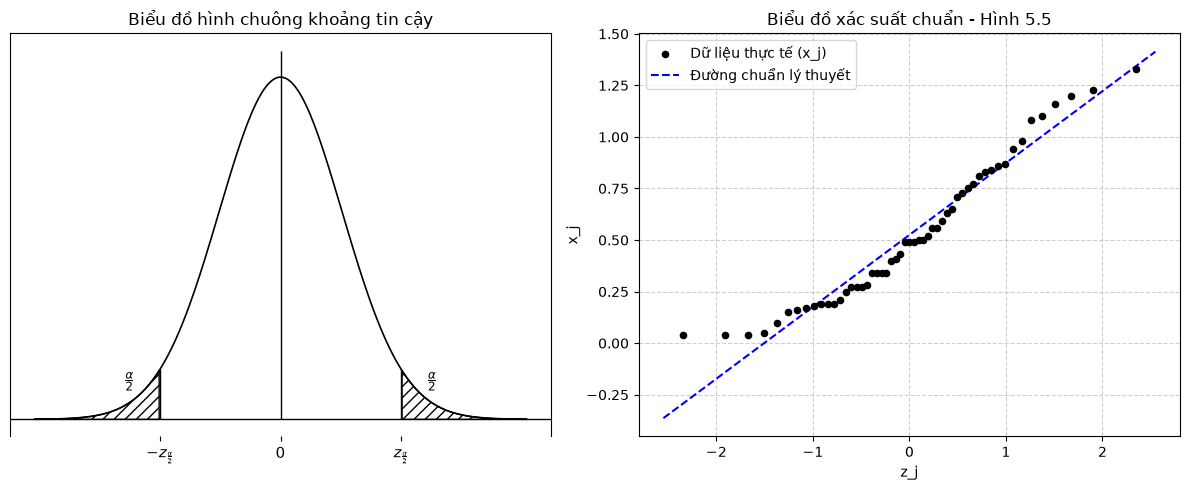

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Khai báo số liệu trực tiếp từ Ví dụ 5.6 (53 hồ ở Florida)
data_goc = np.array([
    1.23, 0.49, 0.49, 1.08, 0.59, 0.28, 0.18, 0.10, 0.94,
    1.33, 0.19, 1.16, 0.98, 0.34, 0.34, 0.19, 0.21, 0.40,
    0.04, 0.83, 0.05, 0.63, 0.34, 0.75, 0.04, 0.86, 0.43,
    0.04, 0.81, 0.15, 0.56, 0.84, 0.87, 0.49, 0.52, 0.25,
    1.20, 0.71, 0.19, 0.41, 0.50, 0.56, 1.10, 0.65, 0.27,
    0.27, 0.50, 0.77, 0.73, 0.34, 0.17, 0.16, 0.27
])

# 2. Sắp xếp số liệu tăng dần và tính đặc trưng mẫu
data_sap_xep = np.sort(data_goc)
n = len(data_sap_xep)
x_tb = np.mean(data_sap_xep)
s = np.std(data_sap_xep, ddof=1)

# 3. Tính khoảng tin cậy 95% (vì n = 53 > 30 nên t xấp xỉ z)
z_alpha_2 = norm.ppf(1 - 0.05 / 2)
sai_so = z_alpha_2 * (s / np.sqrt(n))
can_duoi = x_tb - sai_so
can_tren = x_tb + sai_so

print("--- KẾT QUẢ VÍ DỤ 5.6 ---")
print(f"Cỡ mẫu (n)                : {n}")
print(f"Trung bình mẫu            : {x_tb:.2f}")
print(f"Độ lệch chuẩn mẫu (s)     : {s:.2f}")
print(f"Sai số                    : {sai_so:.2f}")
print(f"Khoảng tin cậy 95% của mu : ({can_duoi:.2f} < mu < {can_tren:.2f})\n")

# 4. Tính toán thông số cho biểu đồ xác suất chuẩn (Hình 5.5)
j = np.arange(1, n + 1)
p_j = (j - 0.5) / n
z_j = norm.ppf(p_j)

# 5. Vẽ biểu đồ
plt.figure(figsize=(12, 5))

# Biểu đồ 1: Biểu đồ hình chuông tối giản minh họa khoảng tin cậy
ax1 = plt.subplot(1, 2, 1)
z_val = np.linspace(-4, 4, 400)
y_val = norm.pdf(z_val)
y_z = norm.pdf(z_alpha_2) 

plt.plot(z_val, y_val, color='black', lw=1.2)
plt.axhline(0, color='black', lw=1)
plt.vlines([0, -z_alpha_2, z_alpha_2], 0, [norm.pdf(0) + 0.03, y_z, y_z], color='black', lw=1)
plt.fill_between(z_val, 0, y_val, where=(np.abs(z_val) >= z_alpha_2), facecolor='none', edgecolor='black', hatch='///')

plt.text(-z_alpha_2 - 0.5, 0.04, r'$\frac{\alpha}{2}$', fontsize=12, ha='center')
plt.text(z_alpha_2 + 0.5, 0.04, r'$\frac{\alpha}{2}$', fontsize=12, ha='center')
plt.xticks([-z_alpha_2, 0, z_alpha_2], [r'$-z_{\frac{\alpha}{2}}$', '0', r'$z_{\frac{\alpha}{2}}$'], fontsize=11)
plt.yticks([]) 
ax1.spines['bottom'].set_visible(False) 
plt.ylim(-0.02, 0.45)
plt.title('Biểu đồ hình chuông khoảng tin cậy')

# Biểu đồ 2: Biểu đồ xác suất chuẩn (Tái hiện Hình 5.5)
plt.subplot(1, 2, 2)
plt.scatter(z_j, data_sap_xep, color='black', s=20, zorder=5, label='Dữ liệu thực tế (x_j)')
z_line = np.linspace(min(z_j) - 0.2, max(z_j) + 0.2, 100)
plt.plot(z_line, s * z_line + x_tb, color='blue', linestyle='--', label='Đường chuẩn lý thuyết')
plt.title('Biểu đồ xác suất chuẩn - Hình 5.5')
plt.xlabel('z_j')
plt.ylabel('x_j')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()